# Gated attention — 04: Where does gating help, and where does it hurt?

We join the held-out **word-occurrence table** (notebook 01) with per-token losses from three conditions on identical tokens:
- **baseline** model,
- **learned G1** (the gated model with its own gates),
- **mean G1** (the same gated model with every gate replaced by its calibration mean; notebook 03).

A word's loss is the **sum** of its subtoken losses ($-\log P$ of the whole word given the prefix). Two paired quantities per word:

- **Gating gain** = baseline loss − learned-G1 loss. Positive ⇒ the gated model gave the observed word more probability.
- **Override cost** = mean-G1 loss − learned-G1 loss. Positive ⇒ replacing the learned gates by fixed means made G1 worse on this word.

Both are computed within each paired seed (G1 seed *s* vs baseline seed *s*) and then averaged over seeds. Categories: **first** mention of a word in its story, and **repeats** binned by the distance (in words) back to the previous occurrence: **1–10**, **11–50**, **51+**. For the distance analysis we separate repeats whose previous occurrence was **visible** inside the model's context window from those that were not (only possible for 51+ in long stories).

In [1]:
import os
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tokenizers import Tokenizer

sys.path.insert(0, str(Path.cwd()))
from gated_attention_model import load_checkpoint, pick_device

RUN_NAME = os.environ.get('GA_RUN', 'smoke')
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments').is_dir())
DATA_DIR = REPO_ROOT / 'processed_data' / 'gated_attention' / RUN_NAME
CKPT_DIR = REPO_ROOT / 'checkpoints' / 'gated_attention' / RUN_NAME
RESULTS_DIR = REPO_ROOT / 'results' / 'gated_attention' / RUN_NAME
device = pick_device()
meta = json.loads((DATA_DIR / 'meta.json').read_text())
SEEDS = json.loads((RESULTS_DIR / 'train_config.json').read_text())['seeds']
tokenizer = Tokenizer.from_file(str(DATA_DIR / 'tokenizer.json'))

words = pd.read_parquet(DATA_DIR / 'eval_words.parquet')
wide = pd.read_parquet(RESULTS_DIR / 'g1_intervention_wide.parquet')     # seed, story_id, target_pos, learned, mean, shuffled, baseline
eval_windows = pd.read_parquet(DATA_DIR / 'eval_windows.parquet')
print(f'{len(words):,} words, {len(wide):,} token-loss rows, seeds {SEEDS}')

650,682 words, 2,517,597 token-loss rows, seeds [0, 1, 2]


## Word-level losses

Every story target is scored exactly once, so the token losses of a story form a contiguous array indexed by `target_pos`. A word's loss is a difference of cumulative sums over its token span `[tok_start, tok_end)`.

In [2]:
CONDS = ['baseline', 'learned', 'mean', 'shuffled']
word_losses = []
for seed in SEEDS:
    d = wide[wide.seed == seed].sort_values(['story_id', 'target_pos']).reset_index(drop=True)
    first_row = d.groupby('story_id').cumcount() == 0
    story_start = pd.Series(d.index[first_row], index=d.story_id[first_row])
    assert (d.target_pos.values == d.index - story_start[d.story_id].values).all()   # contiguous 0..n-1 per story
    start = story_start[words.story_id].values
    out = words[['word_id']].copy()
    out['seed'] = seed
    for c in CONDS:
        cs = np.concatenate([[0.0], np.cumsum(d[c].values.astype(np.float64))])
        out[c] = cs[start + words.tok_end.values] - cs[start + words.tok_start.values]
    word_losses.append(out)
word_losses = pd.concat(word_losses, ignore_index=True)
word_losses['gain'] = word_losses.baseline - word_losses.learned
word_losses['override_cost'] = word_losses['mean'] - word_losses.learned
word_losses.to_parquet(RESULTS_DIR / 'word_losses.parquet', index=False)

# average over paired seeds -> one row per word occurrence
per_word = word_losses.groupby('word_id')[CONDS + ['gain', 'override_cost']].mean()
W = words.set_index('word_id').join(per_word)
W['group'] = np.select(
    [W.occurrence == 'first', W.distance_words <= 10, W.distance_words <= 50, W.prev_visible == True],
    ['first', 'repeat 1-10', 'repeat 11-50', 'repeat 51+ (visible)'], 'repeat 51+ (not visible)')
GROUPS = ['first', 'repeat 1-10', 'repeat 11-50', 'repeat 51+ (visible)', 'repeat 51+ (not visible)']
W[['surface', 'occurrence', 'distance_words', 'n_subtokens', 'group'] + CONDS + ['gain', 'override_cost']].head()

,surface,occurrence,distance_words,n_subtokens,group,baseline,learned,mean,shuffled,gain,override_cost
word_id,,,,,,,,,,,
0,Once,first,NaN,1,first,0.423039,0.356231,1.745754,0.356235,0.066808,1.389523
1,upon,first,NaN,1,first,0.131123,0.098140,0.888196,0.120392,0.032983,0.790057
2,a,first,NaN,1,first,0.003315,0.002075,0.225642,0.011228,0.001240,0.223567
3,time,first,NaN,1,first,0.001182,0.000530,3.401740,0.021284,0.000652,3.401211
4,there,first,NaN,1,first,1.426961,1.373545,1.780958,1.558116,0.053416,0.407413


## First mentions vs repeats

Mean word loss (nats per word) and the two paired quantities, per category. Intervals: 95% from resampling **whole eval stories** (seed-averaged values). Sample counts are shown in the `n` column.

In [3]:
def story_bootstrap_means(df, cols, n_boot=2000, seed=0):
    """Mean of each column and its story-resampled 95% interval."""
    g = df.groupby('story_id')[cols].agg(['sum', 'count'])
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(g), size=(n_boot, len(g)))
    out = {}
    for c in cols:
        s, n = g[(c, 'sum')].to_numpy(), g[(c, 'count')].to_numpy()
        boots = s[idx].sum(1) / n[idx].sum(1)
        out[c] = (s.sum() / n.sum(), np.percentile(boots, 2.5), np.percentile(boots, 97.5))
    return out


rows = []
for grp in GROUPS:
    d = W[W.group == grp].reset_index()
    if len(d) == 0:
        continue
    bs = story_bootstrap_means(d, ['gain', 'override_cost'])
    rows.append(dict(group=grp, n=len(d), stories=d.story_id.nunique(), multi_token_share=(d.n_subtokens > 1).mean(),
                     baseline=d.baseline.mean(), learned=d.learned.mean(), mean_gate=d['mean'].mean(),
                     gain=bs['gain'][0], gain_lo=bs['gain'][1], gain_hi=bs['gain'][2],
                     override=bs['override_cost'][0], override_lo=bs['override_cost'][1], override_hi=bs['override_cost'][2]))
category_table = pd.DataFrame(rows)
category_table.to_csv(RESULTS_DIR / 'word_category_table.csv', index=False)
category_table.round(4)

,group,n,stories,multi_token_share,baseline,learned,mean_gate,gain,gain_lo,gain_hi,override,override_lo,override_hi
0,first,331458,4000,0.0660,3.1120,3.0986,3.4815,0.0134,0.0120,0.0149,0.3829,0.3803,0.3856
1,repeat 1-10,90697,4000,0.0288,1.4811,1.4696,1.7074,0.0115,0.0089,0.0139,0.2377,0.2322,0.2437
2,repeat 11-50,172677,3999,0.0509,1.8582,1.8422,2.1943,0.0161,0.0137,0.0182,0.3521,0.3468,0.3578
3,repeat 51+ (visible),51597,3966,0.0406,2.6394,2.6109,2.9086,0.0285,0.0243,0.0324,0.2977,0.2913,0.3046
4,repeat 51+ (not visible),4253,398,0.0400,3.1921,3.1809,3.3934,0.0113,-0.0017,0.0233,0.2126,0.1939,0.2306


### The same comparison for each paired seed

Seed-to-seed variation (training randomness) is shown separately from the story-resampling intervals above.

In [4]:
wl = word_losses.merge(W[['group']], left_on='word_id', right_index=True)
per_seed = wl.groupby(['group', 'seed'])[['gain', 'override_cost']].mean().unstack('seed').reindex(GROUPS)
per_seed.round(4)

gain                 override_cost                
seed                           0       1       2             0       1       2
group                                                                         
first                     0.0163  0.0062  0.0178        0.3213  0.4383  0.3891
repeat 1-10               0.0069  0.0074  0.0202        0.2112  0.2747  0.2273
repeat 11-50              0.0045 -0.0052  0.0488        0.3336  0.3595  0.3633
repeat 51+ (visible)      0.0237  0.0147  0.0470        0.2943  0.2834  0.3155
repeat 51+ (not visible)  0.0204 -0.0030  0.0163        0.2774  0.1733  0.1871

### Controls: subtoken count and word identity

Repeats are more often common single-token words than first mentions are, so differences between categories could just reflect *which* words fall in each category. Two checks:
1. split by subtoken count (1 vs 2+);
2. **within-type comparison**: for each normalized word type that occurs both as a first mention and as a repeat, take (mean over its repeats) − (mean over its first mentions), then average over types. This compares the same word across categories.

In [5]:
W['subtokens'] = np.where(W.n_subtokens == 1, '1 token', '2+ tokens')
W.pivot_table(index='group', columns='subtokens', values=['gain', 'override_cost'], aggfunc='mean').reindex(GROUPS).round(4)

gain           override_cost          
subtokens                1 token 2+ tokens       1 token 2+ tokens
group                                                             
first                     0.0086    0.0813        0.3371    1.0313
repeat 1-10               0.0129   -0.0362        0.1982    1.5719
repeat 11-50              0.0164    0.0091        0.2751    1.7885
repeat 51+ (visible)      0.0295    0.0053        0.2475    1.4848
repeat 51+ (not visible)  0.0091    0.0627        0.1869    0.8289

In [6]:
by_type = W.groupby(['norm', 'occurrence'])[['gain', 'override_cost']].mean().unstack('occurrence').dropna()
within = pd.DataFrame({q: by_type[(q, 'repeat')] - by_type[(q, 'first')] for q in ['gain', 'override_cost']})
rng = np.random.default_rng(0)
boot = np.array([within.iloc[rng.integers(0, len(within), len(within))].mean().values for _ in range(2000)])
within_summary = pd.DataFrame({'repeat − first (mean over word types)': within.mean(),
                               'ci_low': np.percentile(boot, 2.5, axis=0), 'ci_high': np.percentile(boot, 97.5, axis=0)})
print(f'{len(within)} word types occur both as first mention and as repeat')
within_summary.round(4)

3837 word types occur both as first mention and as repeat


,repeat − first (mean over word types),ci_low,ci_high
gain,-0.0005,-0.0212,0.0202
override_cost,0.3716,0.3333,0.4091


### Function words, content words, and capitalized words

Capitalized words that are not sentence-initial are mostly character names — the classic case where copying from earlier in the story is needed.

In [7]:
W['word_class'] = np.select([W.is_capitalized, W.is_function_word], ['capitalized (names)', 'function word'], 'content word')
W.pivot_table(index='word_class', columns='occurrence', values=['gain', 'override_cost'], aggfunc='mean').round(4)

gain         override_cost        
occurrence            first  repeat         first  repeat
word_class                                               
capitalized (names)  0.0175  0.0392        0.9533  1.2365
content word         0.0155  0.0297        0.4218  0.6373
function word        0.0091  0.0093        0.2824  0.1019

In [8]:
W.pivot_table(index='word_class', columns='occurrence', values='gain', aggfunc='size')

occurrence,first,repeat
word_class,,
capitalized (names),4345,11615
content word,218056,98842
function word,109057,208767


## Figure: first vs repeat word prediction

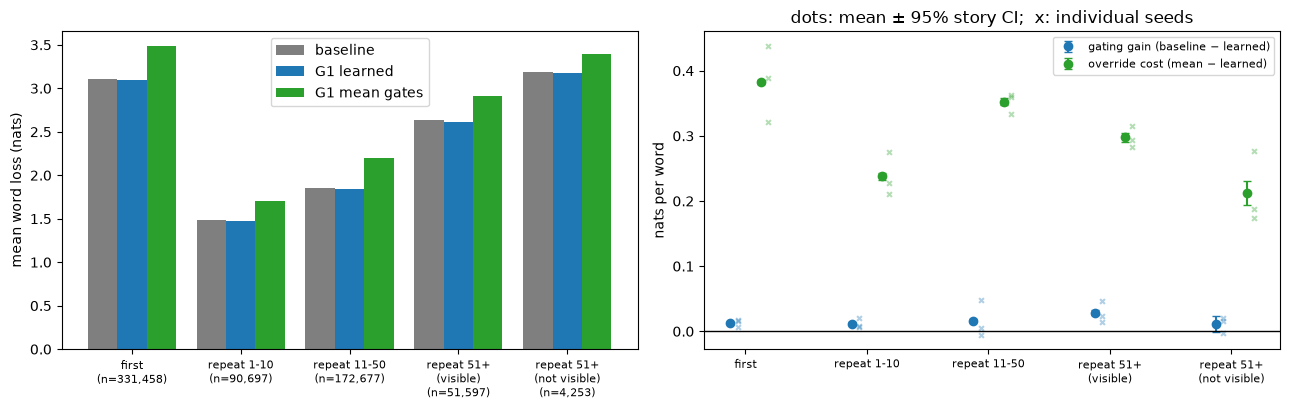

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(category_table))
for k, (col, c, lab) in enumerate([('baseline', 'tab:gray', 'baseline'), ('learned', 'tab:blue', 'G1 learned'),
                                    ('mean_gate', 'tab:green', 'G1 mean gates')]):
    axes[0].bar(x + (k - 1) * 0.27, category_table[col], width=0.27, color=c, label=lab)
axes[0].set_xticks(x, [f"{g.replace(' (', chr(10) + '(')}\n(n={n:,})" for g, n in zip(category_table.group, category_table.n)], fontsize=8)
axes[0].set_ylabel('mean word loss (nats)')
axes[0].legend()
for k, (q, c, lab) in enumerate([('gain', 'tab:blue', 'gating gain (baseline − learned)'),
                                  ('override', 'tab:green', 'override cost (mean − learned)')]):
    y = category_table[q]
    axes[1].errorbar(x + (k - .5) * 0.25, y, yerr=[y - category_table[q + '_lo'], category_table[q + '_hi'] - y],
                     fmt='o', color=c, capsize=3, label=lab)
    col = 'gain' if q == 'gain' else 'override_cost'
    for j, s in enumerate(SEEDS):
        axes[1].scatter(x + (k - .5) * 0.25 + 0.06, per_seed[(col, s)].reindex(category_table.group).values,
                        color=c, alpha=.35, s=12, marker='x')
axes[1].axhline(0, color='k', lw=1)
axes[1].set_xticks(x, [g.replace(' (', '\n(') for g in category_table.group], fontsize=8)
axes[1].set_ylabel('nats per word')
axes[1].set_title('dots: mean ± 95% story CI;  x: individual seeds')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_first_vs_repeat.png', dpi=150)
plt.show()

## Inspecting examples

Two sets:
- **both positive**: G1 with learned gates beats the baseline *and* beats its own mean-gated version — the input-specific gates help this word;
- **both negative**: the learned gates make this word worse than both alternatives.

Words in the first 8 tokens of a story are skipped (almost no prefix to show). For each set we show the most extreme cases and representative ones (drawn near the median of the set). Model outputs come from the seed-0 checkpoints. For each word we show the prefix, the observed word, each condition's probability of the whole word, and each condition's **top next token** at the word's first position. When the word has several subtokens, the top prediction is compared with its **first subtoken** and is labeled that way.

The gate shown is the one used to predict the word's first subtoken, i.e. the gate at the **preceding input position**. We report how far it is from the calibration mean in each layer.

In [10]:
seed0 = SEEDS[0]
models = {name: load_checkpoint(CKPT_DIR / f'{v}_seed{seed0}' / 'best.pt', device)[0]
          for name, v in [('baseline', 'baseline'), ('g1', 'g1')]}
gate_means = torch.tensor(np.load(RESULTS_DIR / 'g1_calibration_gate_means.npy')[SEEDS.index(seed0)],
                          dtype=torch.float32, device=device)
mean_override = {l: gate_means[l] for l in range(models['g1'].n_layer)}
win_by_story = {sid: g.sort_values('offset') for sid, g in eval_windows.groupby('story_id')}
W0 = words.set_index('word_id').join(word_losses[word_losses.seed == seed0].set_index('word_id')[CONDS + ['gain', 'override_cost']])
W0['group'] = W.group


@torch.no_grad()
def inspect(word_id, prefix_words=25):
    r = W0.loc[word_id]
    win = win_by_story[r.story_id]
    win = win[win.offset == r.window_offset].iloc[0]
    p = r.tok_start - win.offset                    # input position that predicts the first subtoken
    x = torch.tensor([list(win.tokens[:p + 1])], device=device)
    out = {}
    for name, model, kw in [('baseline', models['baseline'], {}), ('G1 learned', models['g1'], {}),
                            ('G1 mean', models['g1'], {'gate_override': mean_override})]:
        logits, info = model(x, return_gates=True, **kw)
        top = logits[0, -1].argmax().item()
        out[name] = tokenizer.decode([top])
        if name == 'G1 learned':
            g = torch.stack([gg[0, -1] for gg in info['gates']])            # [L, H] gate at preceding input position
            dev = (g - gate_means).abs()
    prefix = tokenizer.decode(list(win.tokens[1 if win.offset == 0 else 0:p + 1]))
    prefix = ' '.join(prefix.split()[-prefix_words:])
    first_sub = tokenizer.decode([int(win.tokens[p + 1])])
    label = 'top token' if r.n_subtokens == 1 else f'top token (vs first subtoken {first_sub!r} of {r.n_subtokens})'
    return {'prefix': '…' + prefix, 'word': r.surface, 'group': r.group,
            'P baseline': np.exp(-r.baseline), 'P G1 learned': np.exp(-r.learned), 'P G1 mean': np.exp(-r['mean']),
            'gain': r.gain, 'override': r.override_cost, 'label': label,
            **{f'{label} — {k}': v for k, v in out.items()},
            'gate |learned−mean| per layer (max head)': [round(float(v), 2) for v in dev.max(1).values.cpu()]}


def show(word_ids, title):
    print('=' * 100, '\n', title)
    for wid in word_ids:
        d = inspect(wid)
        print('-' * 100)
        print(f"[{d['group']}] {d['prefix']}  ⟶  {d['word']!r}")
        print(f"   P(word): baseline {d['P baseline']:.3g} | G1 learned {d['P G1 learned']:.3g} | G1 mean {d['P G1 mean']:.3g}"
              f"   (gain {d['gain']:+.2f}, override cost {d['override']:+.2f} nats)")
        tops = {k.split(' — ')[1]: v for k, v in d.items() if ' — ' in k and k.startswith(d['label'])}
        print(f"   {d['label']}: " + ' | '.join(f'{k}: {v!r}' for k, v in tops.items()))
        print(f"   gate |learned − calibration mean| (largest head) per layer: {d['gate |learned−mean| per layer (max head)']}")


both_pos = W0[(W0.gain > 0) & (W0.override_cost > 0)]
both_neg = W0[(W0.gain < 0) & (W0.override_cost < 0)]
# examples need a prefix: skip the first word of a story (predicted from EOS alone)
ex_pos, ex_neg = both_pos[both_pos.tok_start >= 8], both_neg[both_neg.tok_start >= 8]
print(f'seed {seed0}: both positive {len(both_pos):,} words ({len(both_pos) / len(W0):.1%}); '
      f'both negative {len(both_neg):,} ({len(both_neg) / len(W0):.1%})')
pd.crosstab(W0.group, [W0.gain > 0, W0.override_cost > 0], normalize='index').round(3).reindex(GROUPS)

seed 0: both positive 243,563 words (37.4%); both negative 120,198 (18.5%)


gain                      False         True        
override_cost             False  True   False  True 
group                                               
first                     0.178  0.303  0.136  0.384
repeat 1-10               0.202  0.277  0.162  0.359
repeat 11-50              0.188  0.306  0.141  0.365
repeat 51+ (visible)      0.189  0.298  0.143  0.370
repeat 51+ (not visible)  0.185  0.302  0.151  0.361

In [11]:
def extremes(df, sign, k=4):
    score = np.minimum(df.gain, df.override_cost) if sign > 0 else -np.maximum(df.gain, df.override_cost)
    return score.sort_values(ascending=False).index[:k].tolist()


def representative(df, k=4, seed=0):
    score = np.minimum(df.gain.abs(), df.override_cost.abs())
    near = score[(score >= score.quantile(.4)) & (score <= score.quantile(.6))]
    return near.sample(min(k, len(near)), random_state=seed).index.tolist()


show(extremes(ex_pos, +1), 'BOTH POSITIVE — extremes (learned gates help most)')
show(representative(ex_pos), 'BOTH POSITIVE — representative (near the median of the set)')

 BOTH POSITIVE — extremes (learned gates help most)
----------------------------------------------------------------------------------------------------
[repeat 1-10] …who liked to play outside. One day, they saw a big bird with a red head and a yellow beak. It was a woodpecker. The  ⟶  'woodpecker'
   P(word): baseline 7.29e-14 | G1 learned 3.4e-10 | G1 mean 3.86e-13   (gain +8.45, override cost +6.78 nats)
   top token (vs first subtoken ' wood' of 4): baseline: ' bird' | G1 learned: ' bird' | G1 mean: ' man'
   gate |learned − calibration mean| (largest head) per layer: [0.18, 0.34, 0.44, 0.44]
----------------------------------------------------------------------------------------------------
[first] …sea with her mom and dad. They all had fun playing in the water and collecting seashells. Suddenly, Lily saw a big pile of dirty  ⟶  'seaweed'
   P(word): baseline 2.42e-08 | G1 learned 2.23e-05 | G1 mean 2.77e-08   (gain +6.83, override cost +6.69 nats)
   top token (vs first subtoke

----------------------------------------------------------------------------------------------------
[repeat 51+ (visible)] …was steaming in the hot sun and the two friends couldn't wait to dive in! They started playing in the water, splashing and laughing. Suddenly  ⟶  'Sunshine'
   P(word): baseline 1.07e-08 | G1 learned 6.78e-06 | G1 mean 1.28e-09   (gain +6.46, override cost +8.58 nats)
   top token (vs first subtoken ' S' of 3): baseline: ',' | G1 learned: ',' | G1 mean: ','
   gate |learned − calibration mean| (largest head) per layer: [0.23, 0.19, 0.31, 0.23]
----------------------------------------------------------------------------------------------------
[repeat 11-50] …you like to eat today?" Tori said, "I want an apple and a cheese sandwich!" So Mommy got the apple and the cheese and helped  ⟶  'Tori'
   P(word): baseline 7.43e-06 | G1 learned 0.0043 | G1 mean 7.58e-07   (gain +6.36, override cost +8.64 nats)
   top token (vs first subtoken ' T' of 3): baseline: ' T' | G1 

----------------------------------------------------------------------------------------------------
[repeat 11-50] …and put it on the table. She said, "See? You have to make it straight and balanced. Then you put another block on top of  ⟶  'it'
   P(word): baseline 0.0575 | G1 learned 0.0723 | G1 mean 0.0358   (gain +0.23, override cost +0.70 nats)
   top token: baseline: ' the' | G1 learned: ' the' | G1 mean: ' the'
   gate |learned − calibration mean| (largest head) per layer: [0.41, 0.14, 0.26, 0.32]
----------------------------------------------------------------------------------------------------
[first] …the frog and carried it to the other side of the road. Lily asked her mommy, "Why did you help the ugly frog?" Her mommy  ⟶  'replied'
   P(word): baseline 0.211 | G1 learned 0.262 | G1 mean 0.137   (gain +0.21, override cost +0.65 nats)
   top token: baseline: ' said' | G1 learned: ' said' | G1 mean: ' said'
   gate |learned − calibration mean| (largest head) per layer: [0.14

In [12]:
show(extremes(ex_neg, -1), 'BOTH NEGATIVE — extremes (learned gates hurt most)')
show(representative(ex_neg), 'BOTH NEGATIVE — representative (near the median of the set)')

 BOTH NEGATIVE — extremes (learned gates hurt most)
----------------------------------------------------------------------------------------------------
[repeat 1-10] …got scared. The rabbit became very angry and ran at Sara. The rabbit was too fast and knocked the pen out of Sara's hand. The  ⟶  'pen'
   P(word): baseline 0.023 | G1 learned 2.83e-05 | G1 mean 0.00375   (gain -6.70, override cost -4.89 nats)
   top token: baseline: ' hat' | G1 learned: ' rabbit' | G1 mean: ' rabbit'
   gate |learned − calibration mean| (largest head) per layer: [0.21, 0.28, 0.43, 0.45]
----------------------------------------------------------------------------------------------------
[first] …on your bed, you might break it!" Timmy didn't listen to his mom and continued to jump on his bed. Suddenly, he heard a loud  ⟶  'CRACK'
   P(word): baseline 1.48e-14 | G1 learned 1.29e-16 | G1 mean 4.04e-14   (gain -4.75, override cost -5.75 nats)
   top token (vs first subtoken ' C' of 5): baseline: ' noise' | 

----------------------------------------------------------------------------------------------------
[repeat 51+ (visible)] …Lily, you can wear your suit. You look very pretty in it. Come on, let's go." Lily took her mom's hand. They walked to the  ⟶  'park'
   P(word): baseline 0.199 | G1 learned 0.134 | G1 mean 0.159   (gain -0.39, override cost -0.17 nats)
   top token: baseline: ' fountain' | G1 learned: ' fountain' | G1 mean: ' park'
   gate |learned − calibration mean| (largest head) per layer: [0.34, 0.32, 0.42, 0.4]
----------------------------------------------------------------------------------------------------
[repeat 11-50] …so jealous of all the other grown ups who could marry. Then Daisy had an idea. She got a special pot and put it on  ⟶  'her'
   P(word): baseline 0.374 | G1 learned 0.219 | G1 mean 0.275   (gain -0.54, override cost -0.23 nats)
   top token: baseline: ' her' | G1 learned: ' the' | G1 mean: ' the'
   gate |learned − calibration mean| (largest head) per

**How to read these examples.** The only thing that differs between "G1 learned" and "G1 mean" is the gate values (same weights, same tokens). So when the two disagree, the disagreement is caused by how much each head's output was let through at the positions before the word. The baseline is a different network trained with the same data and initialization, so baseline-vs-G1 differences reflect everything training with gates changed, not only the gates at test time.